# Red Wine Quality: Analysis & Classification

Which chemical properties drive red-wine quality ratings? This notebook explores correlations with quality, then trains a Decision Tree and a Random Forest to predict the quality score and compares their accuracy and feature importances.

**Dataset:** `data/wine_data.csv`: 1,599 red *vinho verde* samples from the UCI Wine Quality dataset (11 physicochemical features, quality scored 3–8).

**Techniques:** correlation analysis, scikit-learn `DecisionTreeClassifier` and `RandomForestClassifier`, confusion matrices, feature importance.

1.	What is the most frequently occurring wine quality? What is the highest number in and the lowest number in the quantity column?

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
df = pd.read_csv("data/wine_data.csv")

# Most frequent quality
most_frequent_quality = df['quality'].mode()[0]

# Highest and lowest quality
highest_quality = df['quality'].max()
lowest_quality = df['quality'].min()

print("Most Frequently Occurring Quality:", most_frequent_quality)
print("Highest Quality:", highest_quality)
print("Lowest Quality:", lowest_quality)

Most Frequently Occurring Quality: 5
Highest Quality: 8
Lowest Quality: 3


2.	How is `fixed acidity` correlated to the quality of the wine? How does the alcohol content affect the quality? How is the `free Sulphur dioxide` content correlated to the quality of the wine?

In [ ]:
# Correlations
corr_fixed = df['fixed acidity'].corr(df['quality'])
corr_alcohol = df['alcohol'].corr(df['quality'])
corr_free_so2 = df['free sulfur dioxide'].corr(df['quality'])

print("Correlation with Quality:")
print("Fixed Acidity:", corr_fixed)
print("Alcohol:", corr_alcohol)
print("Free Sulfur Dioxide:", corr_free_so2)


Correlation with Quality:
Fixed Acidity: 0.12405164911322428
Alcohol: 0.4761663239995365
Free Sulfur Dioxide: -0.0506560572442763


3.	What is the average `residual sugar` for the best quality wine and the lowest quality wine in the dataset?

In [ ]:
best_quality = df['quality'].max()
worst_quality = df['quality'].min()

avg_residual_best = df[df['quality'] == best_quality]['residual sugar'].mean()
avg_residual_worst = df[df['quality'] == worst_quality]['residual sugar'].mean()

print("Average Residual Sugar (Best Quality):", avg_residual_best)
print("Average Residual Sugar (Worst Quality):", avg_residual_worst)

Average Residual Sugar (Best Quality): 2.5777777777777775
Average Residual Sugar (Worst Quality): 2.6350000000000002


4.	Does `volatile acidity` has an effect over the quality of the wine samples in the dataset?

Correlation of Volatile Acidity with Quality: -0.390557780264007


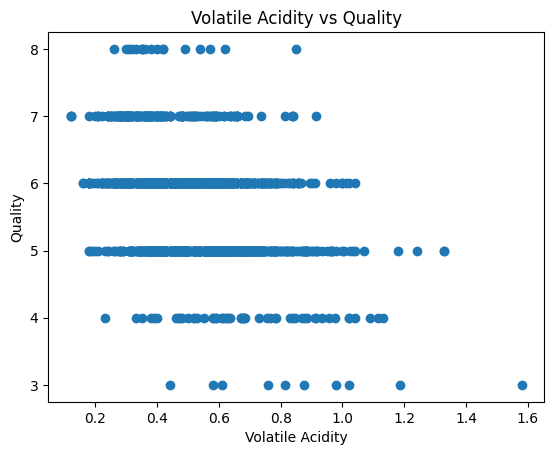

In [ ]:
corr_volatile = df['volatile acidity'].corr(df['quality'])
print("Correlation of Volatile Acidity with Quality:", corr_volatile)

plt.figure()
plt.scatter(df['volatile acidity'], df['quality'])
plt.xlabel("Volatile Acidity")
plt.ylabel("Quality")
plt.title("Volatile Acidity vs Quality")
plt.show()

5.	Train a Decision Tree model and Random Forest Model separately to predict the Quality of the given samples of wine. Compare the Accuracy scores for both models.

In [ ]:
#DECISION TREE MODEL

# Define features and target
X = df.drop('quality', axis=1)
y = df['quality']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print(confusion_matrix(y_test, dt_pred))
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.559375
[[ 0  0  0  1  0  0]
 [ 0  0  5  5  0  0]
 [ 1  4 88 35  2  0]
 [ 0  3 40 70 17  2]
 [ 0  1  5 14 21  1]
 [ 0  0  1  3  1  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.63      0.68      0.65       130
           6       0.55      0.53      0.54       132
           7       0.51      0.50      0.51        42
           8       0.00      0.00      0.00         5

    accuracy                           0.56       320
   macro avg       0.28      0.28      0.28       320
weighted avg       0.55      0.56      0.55       320



In [ ]:
#RANDOM FOREST MODEL

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

importances = rf_model.feature_importances_
feature_names = X.columns

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_df)


Random Forest Accuracy: 0.659375
[[ 0  0  1  0  0  0]
 [ 0  0  7  3  0  0]
 [ 0  0 98 31  1  0]
 [ 0  1 31 91  8  1]
 [ 0  0  0 19 22  1]
 [ 0  0  0  1  4  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.72      0.75      0.73       130
           6       0.63      0.69      0.66       132
           7       0.63      0.52      0.57        42
           8       0.00      0.00      0.00         5

    accuracy                           0.66       320
   macro avg       0.33      0.33      0.33       320
weighted avg       0.63      0.66      0.64       320

                 Feature  Importance
10               alcohol    0.148987
9              sulphates    0.115690
6   total sulfur dioxide    0.102300
1       volatile acidity    0.096902
7                density    0.094191
4              chlorides    0.080256
8                     pH    0.076720
0

In [ ]:
print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Decision Tree Accuracy: 0.559375
Random Forest Accuracy: 0.659375
